# 04 · Expression — EMT-transcription-factor axis along the trajectory

*(Renumbered from 06: with Gate 2 = GO / Gate 3 = NA the manifold is non-branching, so the
branching-only correlation and modules notebooks are not produced — this unconditional expression
notebook follows signatures directly.)*

Puram 2017 overlays **SNAI1** (root) and **ZEB1** (terminus) as the two EMT-TFs marking the ends of its
trajectory. Per the **derive-don't-inherit** mandate we do **not** inherit that pair: we score a
candidate EMT-TF panel — the canonical Snail/Zeb/Twist factors **plus the mesenchymal/neural-crest FOXC
and PRRX factors** — along *this* trajectory, gate on detectable expression, and let the data choose the
most end-specific factor at each end. Deliverable: `expression.pdf`.

In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_in = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

### Load the rooted, signature-scored manifold

The expression step reads the signature-scored manifold (equivalent to `processed.h5ad` plus the fixed
house orientation and pseudotime) so the EMT-TF overlay shares the trajectory layout of every other panel.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime range', round(t.min(),2), '->', round(t.max(),2))

cells: 8920 | pseudotime range 0.0 -> 9.59


### Derive the end-specific EMT-TFs (data-driven)

For each candidate TF we record the fraction of cells expressing it, its mean expression in the early
(root) vs late (terminus) pseudotime tercile, and its Spearman correlation with pseudotime. The most
negatively-correlated sufficiently-expressed factor marks the root end; the most positively-correlated
marks the terminus. Factors below a 3 % expression floor are too sparse to overlay (VIM is excluded — it
is a mesenchymal marker, not a transcription factor).

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]; expr = x > 0
    rho,p = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t'])
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(root)', 'LATE(terminus)')
df = df.sort_values('rho_vs_t')
print('panel present:', present)
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
early_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
late_tf  = ok.sort_values('rho_vs_t').iloc[-1]['TF']
print('\nderived pair: %s (early/root) <-> %s (late/terminus)' % (early_tf, late_tf))

panel present: ['SNAI1', 'SNAI2', 'ZEB1', 'ZEB2', 'TWIST2', 'FOXC1', 'PRRX1', 'PRRX2']
    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
 FOXC1      0.096       0.033      0.009    -0.197    EARLY(root)
 SNAI1      0.052       0.018      0.006    -0.150    EARLY(root)
  ZEB1      0.013       0.004      0.002    -0.072    EARLY(root)
 PRRX1      0.042       0.017      0.008    -0.061    EARLY(root)
 SNAI2      0.006       0.003      0.001    -0.031    EARLY(root)
  ZEB2      0.022       0.004      0.004    -0.024 LATE(terminus)
 PRRX2      0.011       0.003      0.002    -0.020    EARLY(root)
TWIST2      0.045       0.006      0.011     0.013 LATE(terminus)

derived pair: FOXC1 (early/root) <-> TWIST2 (late/terminus)


### EMT-TF expression overlay (deliverable)

House style: `figsize=(3.5,1.5)`, pseudotime left→right, categorical overlay of the strongest expressers
on a grey manifold (not a continuous single-gene colormap). Each factor is thresholded at the upper
quartile of expression among its expressing cells, so only the strongest expressers show and the early
(blue) / late (red) regions separate. The abundant late marker is drawn first so the sparser early
marker reads on top. `size=30` (consistent with every other deliverable panel).

overlay thresholds (upper quartile among expressers): {'FOXC1': 0.231, 'TWIST2': 0.275}
cells shown: {'FOXC1': 213, 'TWIST2': 101}
FOXC1: 9.6% expressing; 213 shown (upper quartile), mean pseudotime of shown = 0.32 (all = 0.50)
TWIST2: 4.5% expressing; 101 shown (upper quartile), mean pseudotime of shown = 0.60 (all = 0.50)
shown-cell pseudotime separation (FOXC1 vs TWIST2) = 0.28
saved expression.pdf


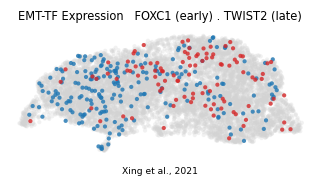

In [5]:
def _vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
thr = {}
for g in [early_tf, late_tf]:
    v = _vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: _vec(g) > thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [early_tf, late_tf]})
print('cells shown:', {g: int(sel[g].sum()) for g in [early_tf, late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))   # abundant first
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('EMT-TF Expression   %s (early) . %s (late)' % (early_tf, late_tf), size=7.5)
ax.text(.5,-.14,'Xing et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
for g in [early_tf, late_tf]:
    m = sel[g]
    print('%s: %.1f%% expressing; %d shown (upper quartile), mean pseudotime of shown = %.2f (all = %.2f)'
          % (g, (_vec(g)>0).mean()*100, int(m.sum()), tn[m].mean(), tn.mean()))
print('shown-cell pseudotime separation (%s vs %s) = %.2f' % (early_tf, late_tf, abs(tn[sel[late_tf]].mean()-tn[sel[early_tf]].mean())))
print('saved expression.pdf')
plt.show()